# Разработка A/B-тестирования и анализ результатов

**Автор:** Куницын Денис

**Дата:** 12 июля

## Цель и задачи

**Бизнес-контекст:** развлекательное приложение с «бесконечной» лентой коротких видео зарабатывает на двух моделях доступа: рекламной (бесплатный контент с рекламными роликами в ленте) и подписочной (ежемесячная оплата полностью отключает рекламу). Главный двигатель продукта — алгоритм рекомендаций: чем интереснее лента, тем дольше пользователь остаётся в приложении.

До недавнего времени лента формировалась на основе простых эвристик («популярное за день + новинки»). Команда Data Science разработала новый алгоритм ранжирования, который учитывает персональные интересы пользователя — прошлые отметки «Нравится» и длительность просмотра — и оптимизирован на вероятность глубокого вовлечения (просмотр более 80% видео). При этом есть два риска для выручки:

1. Пользователи без подписки, максимально поглощённые релевантным контентом, могут начать негативно реагировать на рекламные вставки.
2. Ценность платной подписки «без рекламы» может снизиться, если контент станет слишком поглощающим.

**Цель:** спланировать A/B-тест нового алгоритма рекомендаций, проконтролировать корректность его проведения и оценить результаты.

**Задачи:**

1. Провести исследовательский анализ исторических данных: регистрации, просмотры страниц, доля успешных сессий.
2. Рассчитать необходимый размер выборки и длительность теста.
3. Проконтролировать ход теста: размеры групп, пересечения пользователей, распределение по устройствам и регионам.
4. Проверить гипотезы по целевой, прокси- и барьерной метрикам и дать рекомендацию о внедрении.

## Данные

Используются три таблицы:

- `sessions_history.csv` — исторические данные по сессиям пользователей за период с 2025-08-15 по 2025-09-23;
- `sessions_test_part.csv` — данные за первый день проведения A/B-теста (2025-10-14);
- `sessions_test.csv` — данные за весь период проведения A/B-теста (с 2025-10-14 по 2025-11-02).

Структура таблиц почти совпадает, различаются лишь периоды наблюдения. Поля:

- `user_id` — идентификатор пользователя;
- `session_id` — идентификатор сессии в приложении;
- `session_date` — дата сессии;
- `session_start_ts` — дата и время начала сессии;
- `install_date` — дата установки приложения;
- `session_number` — порядковый номер сессии для конкретного пользователя;
- `registration_flag` — является ли пользователь зарегистрированным;
- `page_counter` — количество просмотренных страниц во время сессии;
- `region` — регион пользователя;
- `device` — тип устройства пользователя;
- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).

> Ссылки на датасеты задаются переменными окружения `SESSIONS_HISTORY_DATASET`, `SESSIONS_TEST_PART_DATASET` и `SESSIONS_TEST_DATASET`.

### Импорт необходимых библиотек и методов

In [2]:
import os

# Импорт инструментов для расчёта мощности теста и эффекта
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Импорт функции для округления вверх
from math import ceil

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from dotenv import load_dotenv

load_dotenv()


### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

Исторические данные о сессиях пользователей загружаются в датафрейм `sessions_history`.

In [3]:
# Загрузка исторических данных о сессиях пользователей
sessions_history = pd.read_csv(os.getenv("SESSIONS_HISTORY_DATASET"))
display(sessions_history.head())

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными

Для каждого пользователя считается количество уникальных сессий. Данные пользователя с наибольшим количеством сессий помогают понять логику формирования каждого столбца.

In [4]:
# Рассчитаем количество уникальных сессий для каждого уникального пользователя
user_sessions = sessions_history.groupby("user_id")["session_id"].nunique().reset_index()
user_sessions.columns = ["user_id", "session_count"]

# Найдем пользователя с наибольшим количеством сессий
max_sessions_user = user_sessions.sort_values(by="session_count", ascending=False).iloc[0]["user_id"]
print(f"Пользователь с максимальным количеством сессий: {max_sessions_user} ({user_sessions.sort_values(by='session_count', ascending=False).iloc[0]['session_count']} сессий)")

# Выведем все данные из sessions_history для этого пользователя
max_user_data = sessions_history[sessions_history["user_id"] == max_sessions_user].sort_values(by="session_start_ts")
display(max_user_data.head(10))


Пользователь с максимальным количеством сессий: 10E0DEFC1ABDBBE0 (10 сессий)


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### Анализ структуры данных:
- Каждая строка в таблице представляет собой одну сессию пользователя в приложении.
- Метрика `session_number` указывает на порядковый номер сессии для конкретного пользователя.
- У пользователя с максимальным количеством сессий (`10E0DEFC1ABDBBE0`) зафиксировано 10 сессий за период наблюдения. Все его сессии совершены с устройства `Android` в регионе `CIS`. Его дата установки (`install_date`) — `2025-08-14`. В день совершается не более одной сессии. Статус `registration_flag` равен `0` на протяжении всех 10 сессий, что означает, что пользователь остался незарегистрированным.


#### 1.3. Анализ числа регистраций

Одна из важнейших метрик продукта — число зарегистрированных пользователей. Пользователь считается зарегистрированным только в день совершения регистрации, поэтому анализируется количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU для регистраций).

Для каждого дня рассчитываются число уникальных пользователей и число зарегистрированных пользователей (у пользователя в течение дня не более одной сессии, а статус регистрации в течение дня не меняется). Строятся графики общего числа пользователей и зарегистрированных пользователей по дням, а также доли зарегистрированных пользователей.

In [5]:
# Приведем даты к формату datetime
sessions_history["session_date"] = pd.to_datetime(sessions_history["session_date"])
sessions_history["session_start_ts"] = pd.to_datetime(sessions_history["session_start_ts"])
sessions_history["install_date"] = pd.to_datetime(sessions_history["install_date"])

# Для каждого дня считаем: общее число уникальных пользователей (DAU)
# и число зарегистрированных активных пользователей (registration_flag == 1 в данный день)
daily_stats = sessions_history.groupby("session_date").agg(
    dau=("user_id", "nunique"),
    registered_dau=("registration_flag", "sum")
).reset_index()

# Доля зарегистрированных пользователей от всех активных
daily_stats["registration_share"] = daily_stats["registered_dau"] / daily_stats["dau"]

# Выведем агрегированные данные для проверки
display(daily_stats.head())

,session_date,dau,registered_dau,registration_share
0,2025-08-11,3919,169,0.043123
1,2025-08-12,6056,336,0.055482
2,2025-08-13,8489,464,0.054659
3,2025-08-14,10321,625,0.060556
4,2025-08-15,14065,840,0.059723


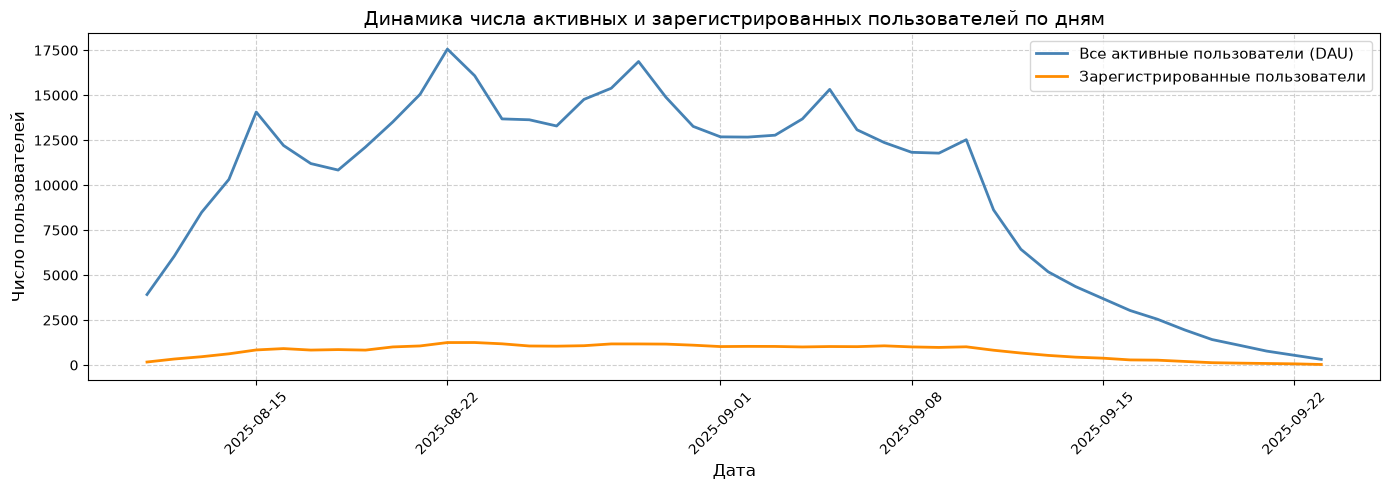

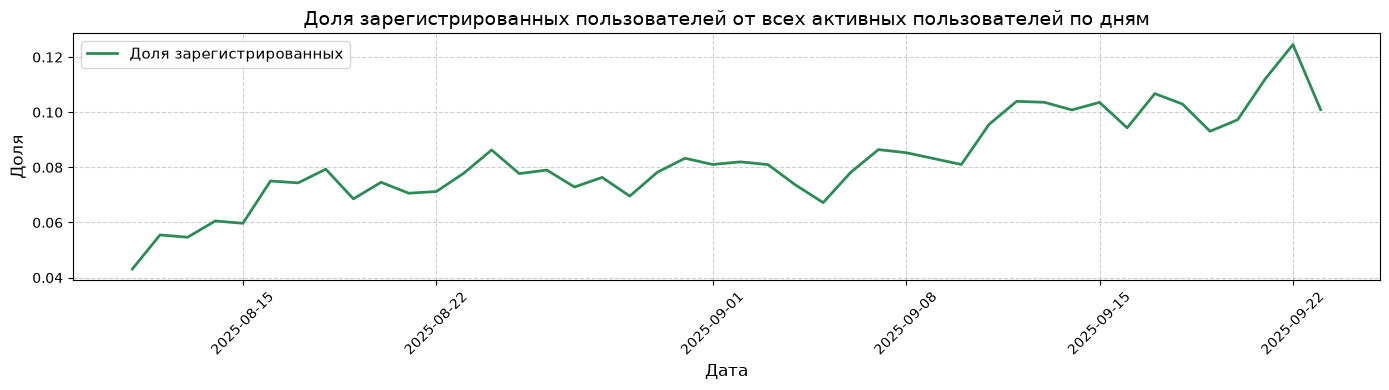

In [6]:
# --- График 1: Общее число пользователей и зарегистрированных по дням ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_stats["session_date"], daily_stats["dau"],
        label="Все активные пользователи (DAU)", color="steelblue", linewidth=2)
ax.plot(daily_stats["session_date"], daily_stats["registered_dau"],
        label="Зарегистрированные пользователи", color="darkorange", linewidth=2)
ax.set_title("Динамика числа активных и зарегистрированных пользователей по дням", fontsize=14)
ax.set_xlabel("Дата", fontsize=12)
ax.set_ylabel("Число пользователей", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- График 2: Доля зарегистрированных пользователей по дням ---
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_stats["session_date"], daily_stats["registration_share"],
        label="Доля зарегистрированных", color="seagreen", linewidth=2)
ax.set_title("Доля зарегистрированных пользователей от всех активных пользователей по дням", fontsize=14)
ax.set_xlabel("Дата", fontsize=12)
ax.set_ylabel("Доля", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

На первом графике виден нехарактерный нисходящий тренд: число активных незарегистрированных пользователей начало значительно уменьшаться. Активность зарегистрированных пользователей также начала уменьшаться, но менее существенно.

In [7]:
daily_stats.tail(20)

,session_date,dau,registered_dau,registration_share
24,2025-09-04,13683,1007,0.073595
25,2025-09-05,15324,1030,0.067215
26,2025-09-06,13078,1023,0.078223
27,2025-09-07,12367,1069,0.086440
28,2025-09-08,11826,1009,0.085320
29,2025-09-09,11780,980,0.083192
30,2025-09-10,12526,1015,0.081031
31,2025-09-11,8623,824,0.095558
32,2025-09-12,6436,669,0.103947
33,2025-09-13,5183,537,0.103608


Активность всех пользователей резко уменьшилась, начиная со второй недели сентября. 

Это может быть связано с началом учебного года: целевой аудиторией развлекательных клипов обычно выступают подростки и молодые люди. Летом у них большое количество свободного времени, которое можно потратить на развлечения подобного рода. Однако, ежедневная активность пользователей падает практически до нуля: стоит обратить внимание на этот тренд, особенно, если такой же не был зафиксирован в прошлые промежутки времени.

#### Анализ динамики регистраций:
- **Общий тренд DAU**: Наблюдается стабильный восходящий тренд, а затем резкий нисходящий, общего числа активных пользователей в день (DAU) - аудитория приложения активно росла в исторический период наблюдения в первый месяц и резко падала во второй месяц. 
- **Статистический тест**: Стоит обратить внимание на период проведения A/B тестирования. Внешние тренды могут повлиять на корректность статистического теста. Для оценки сезонности стоило бы сравнить динамику с историческими данными как минимум за прошлый год, но такие данные недоступны.
- **Динамика зарегистрированных пользователей**: Число зарегистрированных активных пользователей в день (`registration_flag == 1`) также стабильно растёт, что отражает общую тенденцию увеличения аудитории до начала сентября.
- **Доля зарегистрированных от DAU**: Отношение зарегистрированных активных пользователей к общему DAU относительно стабильно по времени, без выраженных резких скачков. Это говорит о том, что соотношение зарегистрированных и незарегистрированных пользователей в аудитории приложения со временем существенно не меняется.

#### 1.4. Анализ числа просмотренных страниц

Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

Анализируется число просмотренных страниц во время первых сессий пользователей: количество первых сессий для каждого значения числа просмотренных страниц.

In [8]:
# Фильтруем первые сессии пользователей
first_sessions = sessions_history[sessions_history["session_number"] == 1]

# Считаем количество первых сессий для каждого значения количества просмотренных страниц
page_counter_dist = first_sessions["page_counter"].value_counts().sort_index().reset_index()
page_counter_dist.columns = ["page_counter", "session_count"]

display(page_counter_dist)


,page_counter,session_count
0,1,8978
1,2,32494
2,3,50939
3,4,32739
4,5,8075
5,6,777
6,7,37


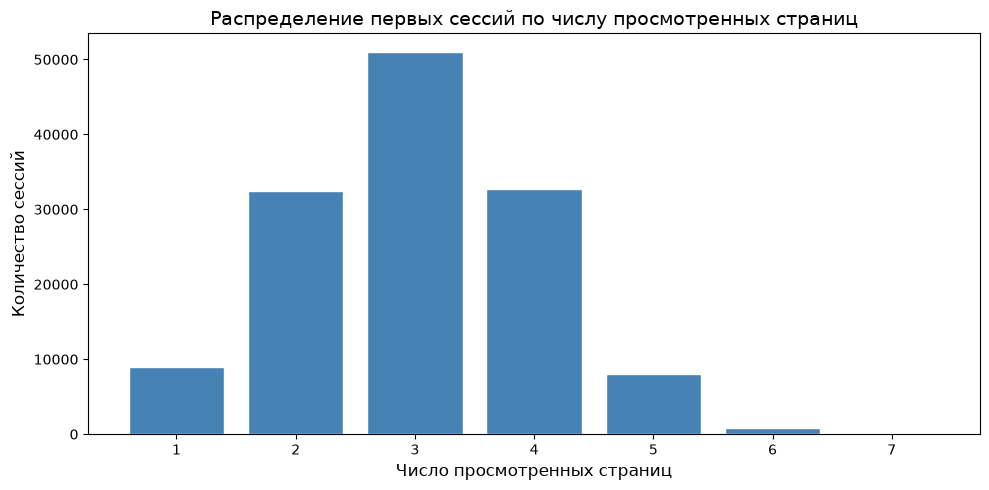

In [9]:
# Столбчатая диаграмма распределения первых сессий по числу просмотренных страниц
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(page_counter_dist["page_counter"], page_counter_dist["session_count"],
       color="steelblue", edgecolor="white")
ax.set_title("Распределение первых сессий по числу просмотренных страниц", fontsize=14)
ax.set_xlabel("Число просмотренных страниц", fontsize=12)
ax.set_ylabel("Количество сессий", fontsize=12)
ax.set_xticks(page_counter_dist["page_counter"])
plt.tight_layout()
plt.show()

#### Анализ распределения просмотренных страниц:
- Распределение имеет форму, близкую к нормальной с пиком на **3 страницах** (50 939 сессий) — наиболее частое поведение в первой сессии.
- Просмотр 2 и 4 страниц занимает второе место по частоте (~32 500 сессий каждый), симметрично относительно пика.
- Только 1 страницу просмотрели в 8 978 сессиях — пользователи редко закрывают приложение сразу после открытия.
- Просмотр 5 страниц встречается заметно реже (8 075 сессий), а 6 и 7 страниц — единичные случаи (777 и 37 сессий соответственно).


#### 1.5. Доля успешных сессий

Продуктовая команда считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель — важная прокси-метрика продукта.

В `sessions_history` добавляется столбец `good_session` (`1` — за сессию просмотрено 4 и более страниц, `0` — меньше), и строится график доли успешных первых сессий по дням за весь период наблюдения.

In [10]:
# В исходном датафрейме sessions_history создаем good_session
sessions_history["good_session"] = (sessions_history["page_counter"] >= 4).astype(int)

# Фильтруем первые сессии
first_sessions = sessions_history[sessions_history["session_number"] == 1]

# Группируем по дате сессии и считаем долю хороших первых сессий
daily_good_sessions = first_sessions.groupby("session_date")["good_session"].mean().reset_index()

display(daily_good_sessions.head())
print(f"Среднее значение доли успешных первых сессий за весь исторический период: {first_sessions['good_session'].mean():.4f}")


,session_date,good_session
0,2025-08-11,0.312835
1,2025-08-12,0.298344
2,2025-08-13,0.306861
3,2025-08-14,0.319098
4,2025-08-15,0.311114


Среднее значение доли успешных первых сессий за весь исторический период: 0.3106


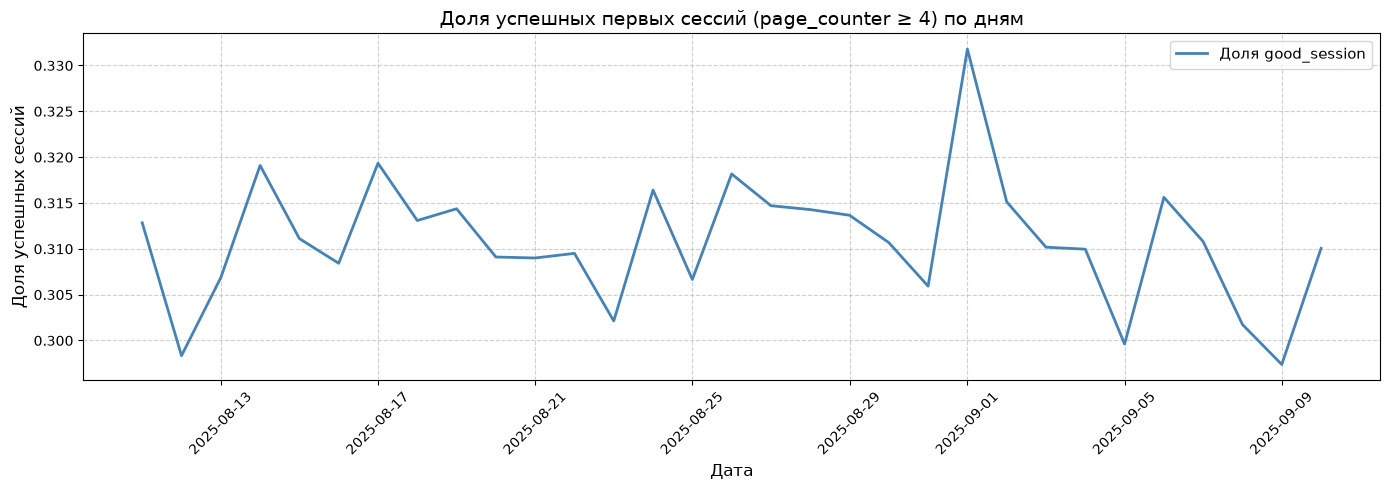

In [11]:
# Линейный график доли успешных первых сессий по дням
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_good_sessions["session_date"], daily_good_sessions["good_session"],
        color="steelblue", linewidth=2, label="Доля good_session")
ax.set_title("Доля успешных первых сессий (page_counter ≥ 4) по дням", fontsize=14)
ax.set_xlabel("Дата", fontsize=12)
ax.set_ylabel("Доля успешных сессий", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Анализ доли успешных сессий:
- Доля успешных первых сессий (`good_session = 1`) колеблется по дням, не демонстрируя выраженного долгосрочного тренда роста или снижения — метрика стабильна на протяжении всего периода наблюдения.
- Среднее историческое значение доли успешных первых сессий составляет **~31.06%**.


### 2. Подготовка к тесту

Планирование теста включает три шага:

- определение целевой метрики;
- расчёт необходимого размера выборки;
- расчёт необходимой длительности теста исходя из текущего трафика.

#### 2.1. Расчёт размера выборки

Размер выборки рассчитывается методом `solve_power()` класса `NormalIndPower` из `statsmodels` со следующими параметрами:

- уровень значимости — 0.05;
- вероятность ошибки второго рода — 0.2 (мощность теста — 0.8);
- минимальный детектируемый эффект (MDE) — 3% относительно базовой доли успешных сессий.

In [12]:
# Задаём параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста (1 - beta)
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p * (1 + mde))

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)

print(f"Необходимый размер выборки для одной группы: {ceil(sample_size)} пользователей")


Необходимый размер выборки для одной группы: 41041 пользователей


#### 2.2. Расчёт длительности A/B-теста

Длительность теста определяется отношением необходимого размера выборок к среднему количеству уникальных пользователей приложения в день; количество дней округляется в большую сторону.

In [13]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = sessions_history.groupby("session_date")["user_id"].nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(2 * sample_size / avg_daily_users)

print(f"Среднее количество уникальных пользователей в день: {avg_daily_users:.2f}")
print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users:.2f} пользователей в день составит {test_duration} дней")

Среднее количество уникальных пользователей в день: 9907.36
Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.36 пользователей в день составит 9 дней


#### Анализ результатов подготовки к тесту:
- Необходимый размер выборки для обнаружения эффекта в 3% при базовой конверсии 30% составляет **41041** пользователь для каждой из групп (контрольной и тестовой).
- Средний дневной трафик приложения равен **9907.36** уникальных пользователей.
- При разделении трафика поровну (50% на группу A и 50% на группу B), в день в каждую группу будет попадать около 4954 уникальных пользователей.
- Округляя длительность в большую сторону, мы получаем **9 дней** для проведения A/B-теста.

**Ограничение расчёта.** Среднее число уникальных пользователей в день рассчитано по всему историческому периоду, однако в конце этого периода наблюдается аномальное снижение активности. Без данных за более длительный срок нельзя определить, на какой участок опираться — конец лета до снижения или период низкой активности в начале учебного года, — поэтому длительность теста стоит считать ориентировочной оценкой.

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест запущен, доступны данные за первый день. На этом этапе проверяется, что пользователи разделены правильно, а интересующие метрики считаются корректно: рассчитывается количество уникальных пользователей в каждой группе и процентная разница между группами:

$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [14]:
# Считаем данные за первый день A/B-теста
sessions_test_part = pd.read_csv(os.getenv("SESSIONS_TEST_PART_DATASET"))

# Рассчитаем количество уникальных пользователей в каждой группе
group_users = sessions_test_part.groupby("test_group")["user_id"].nunique()
print("Уникальные пользователи по группам:")
print(group_users)

# Рассчитаем процентную разницу
a_size = group_users["A"]
b_size = group_users["B"]
pct_diff = 100 * abs(a_size - b_size) / a_size
print(f"\nПроцентная разница размеров групп: {pct_diff:.2f}%")

Уникальные пользователи по группам:
test_group
A    1477
B    1466
Name: user_id, dtype: int64

Процентная разница размеров групп: 0.74%


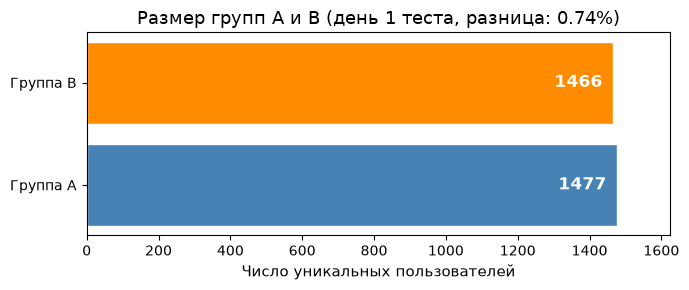

In [15]:
# Cравнение размеров групп
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(["Группа A", "Группа B"], [a_size, b_size],
               color=["steelblue", "darkorange"], edgecolor="white")
for bar, val in zip(bars, [a_size, b_size]):
    ax.text(bar.get_width() - 30, bar.get_y() + bar.get_height() / 2,
            str(val), va="center", ha="right", color="white", fontweight="bold", fontsize=12)
ax.set_title(f"Размер групп A и B (день 1 теста, разница: {pct_diff:.2f}%)", fontsize=13)
ax.set_xlabel("Число уникальных пользователей", fontsize=11)
ax.set_xlim(0, max(a_size, b_size) * 1.1)
plt.tight_layout()
plt.show()

#### 3.2. Проверка пересечений пользователей

Группы должны быть независимы: никто из пользователей не должен попасть в обе группы одновременно.

In [16]:
# Найдем пользователей, которые есть и в группе A, и в группе B
users_a = set(sessions_test_part[sessions_test_part["test_group"] == "A"]["user_id"])
users_b = set(sessions_test_part[sessions_test_part["test_group"] == "B"]["user_id"])
intersect_users = users_a.intersection(users_b)

print(f"Количество пользователей в группе A: {len(users_a)}")
print(f"Количество пользователей в группе B: {len(users_b)}")
print(f"Количество пересекающихся пользователей: {len(intersect_users)}")

Количество пользователей в группе A: 1477
Количество пользователей в группе B: 1466
Количество пересекающихся пользователей: 0


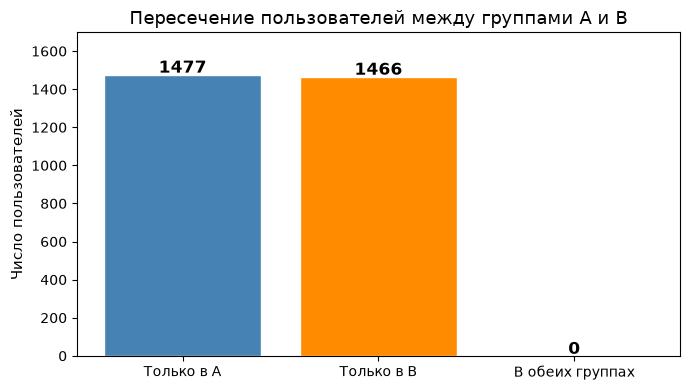

In [17]:
# Уникальные vs пересекающиеся
fig, ax = plt.subplots(figsize=(7, 4))
categories = ["Только в A", "Только в B", "В обеих группах"]
only_a = len(users_a - users_b)
only_b = len(users_b - users_a)
values = [only_a, only_b, len(intersect_users)]
colors = ["steelblue", "darkorange", "crimson"]
bars = ax.bar(categories, values, color=colors, edgecolor="white")
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
            str(val), ha="center", fontweight="bold", fontsize=12)
ax.set_title("Пересечение пользователей между группами A и B", fontsize=13)
ax.set_ylabel("Число пользователей", fontsize=11)
ax.set_ylim(0, max(values) * 1.15)
plt.tight_layout()
plt.show()

#### 3.3. Равномерность разделения пользователей по устройствам

Пользователи должны быть равномерно распределены по всем категориальным переменным. Сравнивается доля каждого типа устройства в группах A и B.

In [18]:
# Получим уникальных пользователей и их устройства
unique_users_devices = sessions_test_part.groupby("user_id").first().reset_index()

# Сгруппируем по группам и устройствам
device_dist = unique_users_devices.groupby(["test_group", "device"])["user_id"].nunique().unstack()
device_pct = device_dist.div(device_dist.sum(axis=1), axis=0) * 100

print("Распределение устройств по группам (абсолютные значения):")
display(device_dist)
print("\nРаспределение устройств по группам (проценты):")
display(device_pct.round(2))

Распределение устройств по группам (абсолютные значения):


device,Android,Mac,PC,iPhone
test_group,,,,
A,656,156,369,296
B,668,148,381,269



Распределение устройств по группам (проценты):


device,Android,Mac,PC,iPhone
test_group,,,,
A,44.41,10.56,24.98,20.04
B,45.57,10.10,25.99,18.35


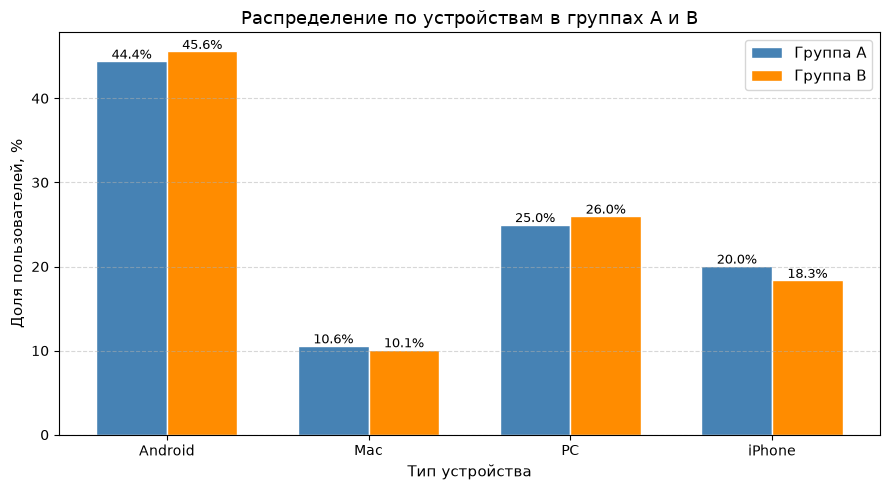

In [19]:
# Доля устройств в группах A и B
x = np.arange(len(device_pct.columns))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
bars_a = ax.bar(x - width/2, device_pct.loc["A"], width, label="Группа A", color="steelblue", edgecolor="white")
bars_b = ax.bar(x + width/2, device_pct.loc["B"], width, label="Группа B", color="darkorange", edgecolor="white")
for bar in list(bars_a) + list(bars_b):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"{bar.get_height():.1f}%", ha="center", fontsize=9)
ax.set_title("Распределение по устройствам в группах A и B", fontsize=13)
ax.set_xlabel("Тип устройства", fontsize=11)
ax.set_ylabel("Доля пользователей, %", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(device_pct.columns)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### 3.4. Равномерность распределения пользователей по регионам

Сравнивается доля каждого региона в группах A и B.

In [20]:
# Получим уникальных пользователей и их регионы
unique_users_regions = sessions_test_part.groupby("user_id").first().reset_index()

# Сгруппируем по группам и регионам
region_dist = unique_users_regions.groupby(["test_group", "region"])["user_id"].nunique().unstack()
region_pct = region_dist.div(region_dist.sum(axis=1), axis=0) * 100

print("Распределение по регионам по группам (абсолютные значения):")
display(region_dist)
print("\nРаспределение по регионам по группам (проценты):")
display(region_pct.round(2))

Распределение по регионам по группам (абсолютные значения):


region,CIS,EU,MENA
test_group,,,
A,644,224,609
B,645,217,604



Распределение по регионам по группам (проценты):


region,CIS,EU,MENA
test_group,,,
A,43.6,15.17,41.23
B,44.0,14.80,41.20


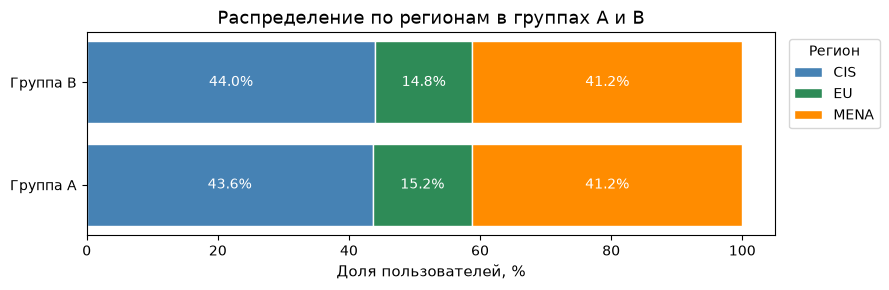

In [21]:
# Доля регионов в группах A и B
colors_regions = ["steelblue", "seagreen", "darkorange"]
fig, ax = plt.subplots(figsize=(9, 3))
left = np.zeros(2)
for col, color in zip(region_pct.columns, colors_regions):
    vals = region_pct[col].values
    bars = ax.barh(["Группа A", "Группа B"], vals, left=left, label=col, color=color, edgecolor="white")
    for bar, val in zip(bars, vals):
        if val > 5:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f"{val:.1f}%", ha="center", va="center", color="white", fontsize=10)
    left += vals
ax.set_title("Распределение по регионам в группах A и B", fontsize=13)
ax.set_xlabel("Доля пользователей, %", fontsize=11)
ax.legend(title="Регион", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=10)
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

### Вывод по результатам мониторинга A/B-теста:
1. **Различие в количестве пользователей**: В первый день теста в группу A попало 1477 уникальных пользователей, в группу B — 1466 уникальных пользователей. Разница составляет всего **0.74%**, что существенно меньше критического порога в 1%. Объемы выборок сбалансированы.
2. **Пересечение пользователей**: Количество пользователей, попавших в обе группы одновременно, равно **0**. Выборки независимы и не пересекаются, система разделения работает корректно.
3. **Равномерность распределения по устройствам**: 
   - Доли устройств в группе A: Android — 44.41%, Mac — 10.56%, PC — 24.98%, iPhone — 20.04%.
   - Доли устройств в группе B: Android — 45.57%, Mac — 10.10%, PC — 25.99%, iPhone — 18.35%.
   - Структура устройств в группах практически идентична.
4. **Равномерность распределения по регионам**:
   - Доли регионов в группе A: CIS — 43.60%, EU — 15.17%, MENA — 41.23%.
   - Доли регионов в группе B: CIS — 44.00%, EU — 14.80%, MENA — 41.20%.
   - Распределение пользователей по географическим сегментам полностью совпадает.

**Заключение**: Мониторинг показывает, что сплитование аудитории проходит корректно. Нарушений в распределении трафика не обнаружено, эксперимент можно продолжать.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, доступны результаты за все дни эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

Полные результаты теста загружаются в датафрейм `sessions_test`, в него добавляется столбец `good_session` (`1` — за сессию просмотрено 4 и более страниц, `0` — меньше).

In [22]:
# Загрузка полных результатов теста
sessions_test = pd.read_csv(os.getenv("SESSIONS_TEST_DATASET"))

# Добавление флага успешной сессии
sessions_test["good_session"] = (sessions_test["page_counter"] >= 4).astype(int)

# Приведение даты к типу datetime
sessions_test["session_date"] = pd.to_datetime(sessions_test["session_date"])
sessions_test["session_start_ts"] = pd.to_datetime(sessions_test["session_start_ts"])
sessions_test["install_date"] = pd.to_datetime(sessions_test["install_date"])

print(f"Размер датафрейма sessions_test: {sessions_test.shape}")
display(sessions_test.head())


Размер датафрейма sessions_test: (100005, 12)


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2. Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

Новый алгоритм рекомендаций, по замыслу команды разработки, должен показывать каждому пользователю более интересный контент. Ниже сформулированы гипотезы эксперимента, а также целевая, прокси- и барьерная метрики.

### Формулировка гипотез:
- **Нулевая гипотеза ($H_0$)**: Доля успешных первых сессий (`good_session`) в контрольной группе A и тестовой группе B равна ($p_A = p_B$). Новый рекомендательный алгоритм не влияет на глубину вовлечённости пользователей.
- **Альтернативная гипотеза ($H_1$)**: Доля успешных первых сессий в группах A и B различается ($p_A \neq p_B$). Новый алгоритм изменяет долю пользователей, просматривающих 4 и более страниц.

### Целевая, прокси- и барьерные метрики:
- **Целевая метрика**: `good_session` — доля первых сессий с просмотром 4 и более страниц. Непосредственно отражает вовлечённость пользователя в контент и является ключевым показателем качества алгоритма рекомендаций.
- **Прокси-метрика**: `page_counter` — среднее число просмотренных страниц за первую сессию. Непрерывная переменная, позволяющая уловить более тонкие изменения в поведении пользователей (например, рост с 3.0 до 3.2 стр.), которые могут быть незаметны в бинарной целевой метрике. Проверяется критерием Манна–Уитни, потому что метрика имеет немного скошенное распределение и критерий будет более консервативен по сравнению с t-тестом.
- **Барьерная метрика**: `registration_flag` — доля пользователей, зарегистрировавшихся во время первой сессии. Новый алгоритм не должен снижать конверсию в регистрацию: падение этого показателя означает негативный побочный эффект и является стоп-сигналом для внедрения.


#### 4.3. Сравнение доли успешных сессий

Доля успешных первых сессий в группах A и B и разница в этом показателе; дополнительно — прокси- и барьерная метрики.

In [23]:
# Фильтруем первые сессии для полных результатов теста
test_first_sessions = sessions_test[sessions_test["session_number"] == 1]

# ── Целевая метрика: good_session ──────────────────────────────────────────
group_shares = test_first_sessions.groupby("test_group")["good_session"].mean()
group_counts = test_first_sessions.groupby("test_group")["good_session"].agg(["count", "sum"])
share_diff = group_shares["B"] - group_shares["A"]

print("=== Целевая метрика: good_session ===")
print(group_counts)
print("\nДоля успешных первых сессий:")
print(group_shares)
print(f"Абсолютная разница (B - A): {share_diff:.4f} ({share_diff*100:.2f}%)")

=== Целевая метрика: good_session ===
            count   sum
test_group             
A           15162  4787
B           15416  4851

Доля успешных первых сессий:
test_group
A    0.315724
B    0.314673
Name: good_session, dtype: float64
Абсолютная разница (B - A): -0.0011 (-0.11%)


In [24]:
# ── Прокси-метрика: page_counter ──────────────────────────────────────────
page_stats = test_first_sessions.groupby("test_group")["page_counter"].agg(["mean", "median"])
print("\n=== Прокси-метрика: page_counter ===")
display(page_stats)


=== Прокси-метрика: page_counter ===


,mean,median
test_group,,
A,3.017412,3.0
B,3.030034,3.0


In [25]:
# ── Барьерная метрика: registration_flag ──────────────────────────────────
reg_counts = test_first_sessions.groupby("test_group")["registration_flag"].agg(["count", "sum"])
reg_shares = test_first_sessions.groupby("test_group")["registration_flag"].mean()
print("\n=== Барьерная метрика: registration_flag ===")
display(reg_counts)
print("Доля зарегистрировавшихся:")
print(reg_shares)
print(f"Абсолютная разница (B - A): {reg_shares['B'] - reg_shares['A']:.4f} ({(reg_shares['B'] - reg_shares['A'])*100:.2f}%)")


=== Барьерная метрика: registration_flag ===


,count,sum
test_group,,
A,15162,644
B,15416,615


Доля зарегистрировавшихся:
test_group
A    0.042475
B    0.039894
Name: registration_flag, dtype: float64
Абсолютная разница (B - A): -0.0026 (-0.26%)


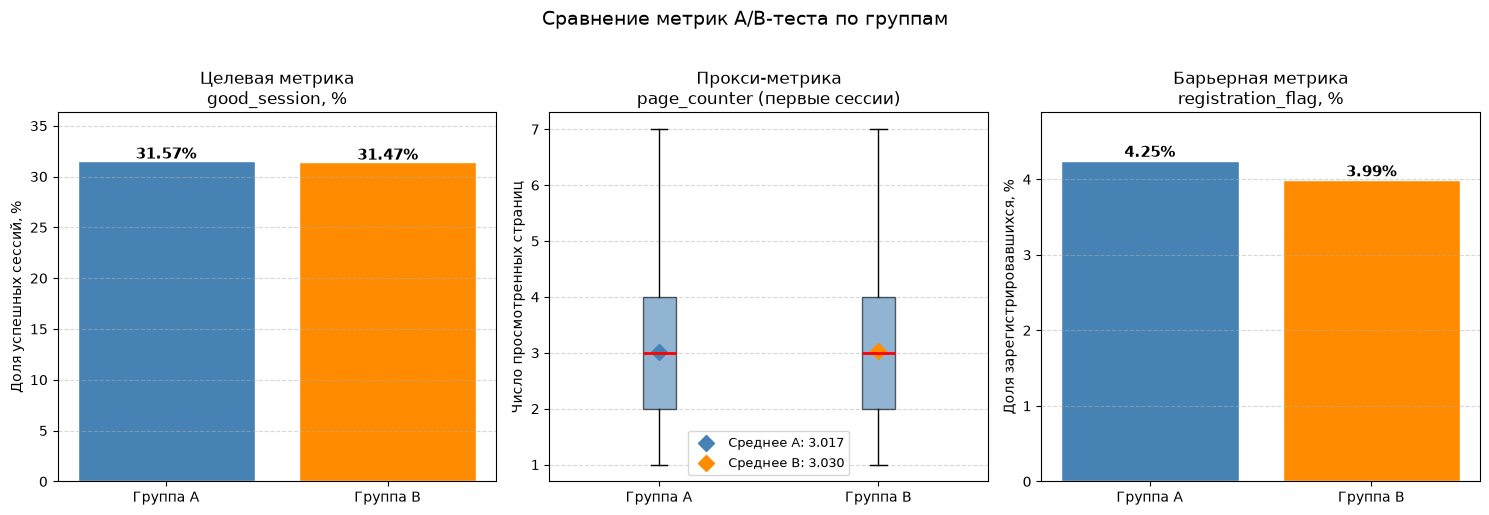

In [26]:
# ── Графики ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1) Целевая: good_session
ax = axes[0]
bars = ax.bar(["Группа A", "Группа B"], group_shares.values * 100,
              color=["steelblue", "darkorange"], edgecolor="white")
for bar, val in zip(bars, group_shares.values * 100):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{val:.2f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_title("Целевая метрика\ngood_session, %", fontsize=12)
ax.set_ylabel("Доля успешных сессий, %")
ax.set_ylim(0, max(group_shares.values)*100 * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# 2) Прокси: page_counter (boxplot)
ax = axes[1]
data_a = test_first_sessions[test_first_sessions["test_group"]=="A"]["page_counter"]
data_b = test_first_sessions[test_first_sessions["test_group"]=="B"]["page_counter"]
ax.boxplot([data_a, data_b], 
           patch_artist=True,
           boxprops=dict(facecolor="steelblue", alpha=0.6),
           medianprops=dict(color="red", linewidth=2))
ax.set_xticklabels(["Группа A", "Группа B"])
for i, (grp, col) in enumerate([("A","steelblue"),("B","darkorange")], 1):
    mean_val = page_stats.loc[grp, "mean"]
    ax.plot(i, mean_val, "D", color=col, markersize=8, label=f"Среднее {grp}: {mean_val:.3f}")
ax.set_title("Прокси-метрика\npage_counter (первые сессии)", fontsize=12)
ax.set_ylabel("Число просмотренных страниц")
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# 3) Барьерная: registration_flag
ax = axes[2]
bars = ax.bar(["Группа A", "Группа B"], reg_shares.values * 100,
              color=["steelblue", "darkorange"], edgecolor="white")
for bar, val in zip(bars, reg_shares.values * 100):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{val:.2f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_title("Барьерная метрика\nregistration_flag, %", fontsize=12)
ax.set_ylabel("Доля зарегистрировавшихся, %")
ax.set_ylim(0, max(reg_shares.values)*100 * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Сравнение метрик A/B-теста по группам", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

#### 4.4. Статистическая значимость изменения ключевой метрики

Доля успешных первых сессий в группе B оказалась на 0.1% ниже, чем в группе A, но делать выводы только на основе этого значения некорректно: необходимо проверить, является ли изменение статистически значимым. Уровень значимости — 0.05.

In [27]:
alpha = 0.05

# ── 1. Целевая: good_session — Z-тест долей ─────────────────────────────
successes = np.array([group_counts.loc["A", "sum"], group_counts.loc["B", "sum"]])
nobs = np.array([group_counts.loc["A", "count"], group_counts.loc["B", "count"]])
z_stat, p_val_gs = proportions_ztest(count=successes, nobs=nobs, alternative="two-sided")
print("=== Целевая метрика: good_session ===")
print(f"Z-статистика: {z_stat:.4f} | p-value: {p_val_gs:.4f}")
print("→", "Отклоняем H0" if p_val_gs < alpha else "Не отклоняем H0",
      f"(p={'<0.001' if p_val_gs < 0.001 else f'{p_val_gs:.4f}'}{' < a' if p_val_gs < alpha else ' >= a'})")

# ── 2. Прокси: page_counter — Mann-Whitney U ─────────────────────────────
from scipy.stats import mannwhitneyu
a_pc = test_first_sessions[test_first_sessions["test_group"]=="A"]["page_counter"]
b_pc = test_first_sessions[test_first_sessions["test_group"]=="B"]["page_counter"]
u_stat, p_val_pc = mannwhitneyu(a_pc, b_pc, alternative="two-sided")
print("\n=== Прокси-метрика: page_counter ===")
print(f"U-статистика: {u_stat:.0f} | p-value: {p_val_pc:.4f}")
print("→", "Отклоняем H0" if p_val_pc < alpha else "Не отклоняем H0",
      f"(p={'<0.001' if p_val_pc < 0.001 else f'{p_val_pc:.4f}'}{' < a' if p_val_pc < alpha else ' >= a'})")

# ── 3. Барьерная: registration_flag — Z-тест долей ───────────────────────
succ_reg = np.array([reg_counts.loc["A", "sum"], reg_counts.loc["B", "sum"]])
nobs_reg = np.array([reg_counts.loc["A", "count"], reg_counts.loc["B", "count"]])
z_reg, p_val_reg = proportions_ztest(count=succ_reg, nobs=nobs_reg, alternative="two-sided")
print("\n=== Барьерная метрика: registration_flag ===")
print(f"Z-статистика: {z_reg:.4f} | p-value: {p_val_reg:.4f}")
print("Отклоняем H0" if p_val_reg < alpha else "Не отклоняем H0",
      f"(p={'<0.001' if p_val_reg < 0.001 else f'{p_val_reg:.4f}'}{' < a' if p_val_reg < alpha else ' >= a'})")
if p_val_reg < alpha and (reg_shares["B"] - reg_shares["A"]) < 0:
    print("БАРЬЕР НАРУШЕН: конверсия в регистрацию в группе B статистически значимо ниже!")
else:
    print("Барьер соблюдён: конверсия в регистрацию не ухудшилась.")


=== Целевая метрика: good_session ===
Z-статистика: 0.1977 | p-value: 0.8433
→ Не отклоняем H0 (p=0.8433 >= a)

=== Прокси-метрика: page_counter ===
U-статистика: 116506734 | p-value: 0.6242
→ Не отклоняем H0 (p=0.6242 >= a)

=== Барьерная метрика: registration_flag ===
Z-статистика: 1.1357 | p-value: 0.2561
Не отклоняем H0 (p=0.2561 >= a)
Барьер соблюдён: конверсия в регистрацию не ухудшилась.


### Итоговый вывод по результатам A/B-эксперимента:
1. **Характеристики эксперимента**: тест проводился с 2025-10-14 по 2025-11-02 (20 дней). Группа A — 15 162 первых сессии, группа B — 15 416; оба объёма превышают минимально необходимый (3 762).

2. **Целевая метрика — `good_session`** (доля первых сессий с page_counter ≥ 4):
   - A: **31.57%**, B: **31.47%** (delta = −0.11%). Z-тест: p = **0.8433** >= 0.05 - H0 **не отклоняется**.

3. **Прокси-метрика — `page_counter`** (среднее число страниц за первую сессию):
   - A: **3.017** стр., B: **3.030** стр. (delta = +0.013). Тест Манна–Уитни: p = **0.6242** >= 0.05 - H0 **не отклоняется**.

4. **Барьерная метрика — `registration_flag`** (доля зарегистрировавшихся):
   - A: **4.25%**, B: **3.99%** (delta = −0.26%). Z-тест: p = **0.2561** >= 0.05 - **барьер соблюдён**, снижение статистически незначимо.

5. **Рекомендация: не внедрять** новый алгоритм рекомендаций.
   Ни целевая метрика, ни прокси не показали статистически значимого улучшения. Барьерная метрика не нарушена, но наблюдается тенденция к снижению конверсии в регистрацию. Внедрение нецелесообразно.
